# Canada on Fire: Seven Decades of Wildfire Patterns, Causes and Extremes
**COMP 6934: Introduction to Data Visualization · Fall 2026 · Group 15**

This notebook reproduces every figure in the report, in report order, with the full plotting code of each figure in its own cell. Data loading and cleaning live in `code/fire_data.py` and the visual system (palette, font, sizes) in `code/style.py`; the figure code below is generated from `code/figures.py`, so the script and the notebook always match. Running top to bottom writes `figures/*.pdf` (for LaTeX) and `figures/*.png`.

**Data:** Canadian National Fire Database (CNFDB), Canadian Forest Service, Natural Resources Canada, https://cwfis.cfs.nrcan.gc.ca/en/fire-history, Open Government Licence – Canada. Point data `NFDB_point_20260811.txt`; burned-area polygons 1972–2024.

**Questions**
1. Is the area burned each year increasing, and how unusual was 2023?
2. How do lightning- and human-caused fires differ in where they happen, when they happen, and how big they get?
3. Do a small number of very large fires account for most of the burned area, and has the typical fire size changed by decade?
4. Where are Canada's main wildfire hotspots, and have they shifted over time?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("code").resolve()))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import fire_data as fd
import style as st

st.apply()
%matplotlib inline

## 1. Data, cleaning and checks
- Years kept: 1950–2025 (drops `YEAR = -999` and 171 sparse pre-1950 records). Most agencies report from 1959; New Brunswick from 1980 and PEI from 2018, so trend tests use **1980–2025** and figures shade the earlier years.
- Cause: H = Human, N = Lightning, U = Unknown (kept and shown, never silently dropped).
- **Province = where the fire burned**, found by a spatial join of each fire point to the province outlines (nearest province within 25 km for coastal points). Parks Canada fires therefore count in their province, and the NWT and Nunavut are separate.
- 40,028 fires have size 0 ha (spot fires). Size figures use fires with a recorded size and say so.
- Seasonal figures drop records with unknown month (`MONTH = 0`).
- The burned-area polygons are simplified to 1 km by `code/prepare_geo.py`, keeping 99.06% of the mapped area. Run it once before the maps.

In [2]:
df = fd.load_fires()
print(f"{len(df):,} fires, {df.YEAR.min()}–{df.YEAR.max()}; "
      f"{df.province.isna().sum()} points outside every province (0.08%)")
df.head()

448,447 fires, 1950–2025; 346 points outside every province (0.08%)


,NFDBFIREID,SRC_AGENCY,LATITUDE,LONGITUDE,YEAR,MONTH,DAY,SIZE_HA,CAUSE,cause,agency,region,decade,size_class,province
0,AB-2024-CWF-001-2024,AB,50.066333,-114.154883,2024,1,2,0.05,H,Human,AB,Alberta,2020,<0.1 ha,Alberta
1,AB-2024-HWF-001-2024,AB,57.912833,-116.334050,2024,1,5,0.40,H,Human,AB,Alberta,2020,0.1-1,Alberta
2,AB-2024-SWF-001-2024,AB,56.575550,-115.216533,2024,1,17,0.01,H,Human,AB,Alberta,2020,<0.1 ha,Alberta
3,AB-2024-LWF-001-2024,AB,55.957361,-110.709667,2024,1,9,0.01,H,Human,AB,Alberta,2020,<0.1 ha,Alberta
4,AB-2024-LWF-002-2024,AB,55.957361,-110.709667,2024,1,9,0.01,H,Human,AB,Alberta,2020,<0.1 ha,Alberta


**Check against the official statistics.** Yearly fire counts and hectares are compared with NRCan's published NFDB summary (`NFDB_point_stats.xlsx`). Only the years listed below differ; all are within 0.6% except 1979, where one record was revised after the summary was produced.

In [3]:
diff = fd.check_official(df)
diff[["fires", "FIRES", "fires_diff", "area_ha", "TOTAL_HA", "ha_diff"]] if len(diff) else diff

,fires,FIRES,fires_diff,area_ha,TOTAL_HA,ha_diff
YEAR,,,,,,
1979,8296,8296,0,2.524529e+06,3.374029e+06,-849500.0
2018,7111,7111,0,2.326357e+06,2.328851e+06,-2494.0
2022,5658,5657,1,1.576205e+06,1.585082e+06,-8878.0
2023,6837,6843,-6,1.760655e+07,1.761206e+07,-5512.0
2025,6215,6196,19,8.707253e+06,8.704995e+06,2258.0


In [4]:
summary = df.groupby("cause", observed=True).agg(
    fires=("SIZE_HA", "size"),
    area_Mha=("SIZE_HA", lambda s: s.sum() / 1e6),
    median_ha=("SIZE_HA", "median"))
summary.round(2)

,fires,area_Mha,median_ha
cause,,,
Lightning,195246,140.56,0.1
Human,242032,19.14,0.1
Unknown,11169,6.85,0.4


## 2. Shared helpers
Trend test (Kendall's tau with a Theil–Sen slope and 95% CI), p-value formatting, waffle drawing, and map helpers used by several figures.

In [5]:
def trend_test(series):
    """Kendall's tau (monotonic trend) and Theil-Sen slope with 95% CI, per year."""
    s = series.dropna()
    tau, p = stats.kendalltau(s.index, s.values)
    slope, _, lo, hi = stats.theilslopes(s.values, s.index)
    return dict(tau=tau, p=p, slope=slope, lo=lo, hi=hi, years=f"{s.index.min()}–{s.index.max()}")


def _p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.2f}"


def _largest_remainder(shares, total=100):
    """Round shares to integers that sum exactly to `total` (waffle must = 100%)."""
    raw = np.asarray(shares, float) / np.sum(shares) * total
    out = np.floor(raw).astype(int)
    for i in np.argsort(raw - out)[::-1][: total - out.sum()]:
        out[i] += 1
    return out


def _waffle(ax, squares, colors, n=10, gap=0.16):
    from matplotlib.patches import FancyBboxPatch
    cells = [c for c, k in zip(colors, squares) for _ in range(k)]
    for i, c in enumerate(cells):                  # fill column-wise from bottom-left
        col, row = divmod(i, n)
        ax.add_patch(FancyBboxPatch((col + gap / 2, row + gap / 2), 1 - gap, 1 - gap,
                                    boxstyle="round,pad=0,rounding_size=0.14", fc=c, ec="none"))
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect("equal")
    ax.axis("off")


NEUTRAL = "#A09A92"   # warm grey: neutral context, not a cause colour


GEO_DIR = st.FIG_DIR.parent / "data_derived"
LAND = "#EFEBE4"


def _load_geo():
    import geopandas as gpd
    prov = gpd.read_file(GEO_DIR / "canada_provinces.gpkg")
    scars = gpd.read_file(GEO_DIR / "burn_scars_1972_2024.gpkg")
    return prov, scars


def _base_map(ax, prov, crop=True, top=0.75):
    prov.plot(ax=ax, color=LAND, edgecolor="white", linewidth=0.6, zorder=0)
    ax.set_axis_off()
    ax.set_aspect("equal")
    if crop:   # trim the fire-free high Arctic so the page is used for the fire belt
        x0, y0, x1, y1 = prov.total_bounds
        ax.set_xlim(x0 + 0.02 * (x1 - x0), x1 - 0.04 * (x1 - x0))
        ax.set_ylim(y0, y0 + top * (y1 - y0))


def scar_centres(scars):
    """Area-weighted centre of burning per decade (projected metres) and Mha per year."""
    c = scars.geometry.representative_point()
    w = scars.SIZE_HA
    g = scars.assign(cx=c.x * w, cy=c.y * w, w=w).groupby("dec")
    out = pd.DataFrame({"x": g.cx.sum() / g.w.sum(), "y": g.cy.sum() / g.w.sum(),
                        "mha_per_year": g.w.sum() / g.YEAR.nunique() / 1e6,
                        "years": g.YEAR.nunique()})
    return out

## 3. Q1: Is the area burned increasing, and how unusual was 2023?

### Figure 1: Fewer fires, extreme worst seasons
**Point this figure supports:** Fires per year have fallen since 1980 (−77 a year, p < 0.001). Area burned has no significant trend over 1980–2025 (Kendall p = 0.10): it swings wildly, and the two largest years on record are 2023 (17.6 Mha, 2.0x any other) and 2025 (8.7 Mha).

In [6]:
def fig1_trend(df):
    y = fd.yearly(df)
    roll = y.rolling(10, min_periods=10).mean()   # trailing: mean of this + previous 9 years
    rec_year = int(y.area_ha.idxmax())
    rec = y.area_ha.max()
    runner_year = int(y.area_ha.drop(rec_year).idxmax())
    runner = y.area_ha.loc[runner_year]
    ta = trend_test(y.area_ha.loc[fd.FULL_REPORTING_FROM:])
    tf = trend_test(y.fires.loc[fd.FULL_REPORTING_FROM:])

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(st.TEXT_WIDTH, 4.6), sharex=True,
                                 gridspec_kw={"height_ratios": [1.7, 1], "hspace": 0.28})
    for ax in (a1, a2):
        ax.axvspan(fd.FIRST_YEAR - 1, fd.FULL_REPORTING_FROM - 0.5, color="#F3F1EC", zorder=0, lw=0)
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)

    # top: hectares
    a1.plot(y.index, y.area_ha, color=st.CONTEXT, lw=1.0, zorder=2)
    a1.plot(roll.index, roll.area_ha, color=st.LIGHTNING, lw=2.0, zorder=3,
            solid_capstyle="round")
    a1.scatter([rec_year], [rec], s=34, color=st.EMBER, zorder=4, edgecolor="white", lw=0.8)
    a1.text(rec_year - 1.8, rec, f"{rec_year}: {rec / 1e6:.1f} million ha", ha="right",
            va="center", fontsize=8.5, color=st.INK, fontweight="bold")
    a1.text(rec_year - 2.2, rec * 0.9, f"{rec / runner:.1f}x the next-worst year",
            ha="right", va="center", fontsize=7.5, color=st.INK)
    a1.scatter([runner_year], [runner], s=22, color=st.INK, zorder=4, edgecolor="white", lw=0.8)
    a1.annotate(f"{runner_year}: {runner / 1e6:.1f} million ha, 2nd largest", xy=(runner_year, runner),
                xytext=(runner_year - 3, runner + 2.4e6), fontsize=7.2, color=st.INK, ha="right",
                va="center", arrowprops=dict(arrowstyle="-", color=st.INK, lw=0.6, shrinkB=3))
    a1.text(fd.FULL_REPORTING_FROM + 1, rec * 0.74,
            f"Trend {ta['years']}: not significant\n"
            f"(Kendall τ = {ta['tau']:.2f}, {_p(ta['p'])})",
            fontsize=7, color=st.MUTED, va="top")
    last = roll.area_ha.dropna()
    a1.text(last.index[-1] + 1.2, last.iloc[-1], "10-year\naverage", color=st.INK,
            fontsize=7.5, fontweight="bold", va="center", ha="left")
    a1.text(1951, rec * 0.97, "Incomplete reporting\nbefore 1980", fontsize=7, color=st.MUTED,
            va="top", style="italic")
    a1.set_ylim(0, rec * 1.08)
    a1.yaxis.set_major_locator(mticker.MultipleLocator(4e6))
    a1.yaxis.set_major_formatter(mticker.FuncFormatter(st.mha))
    a1.set_ylabel("Area burned (million ha)")

    # bottom: number of fires
    a2.plot(y.index, y.fires, color=st.CONTEXT, lw=1.0)
    a2.plot(roll.index, roll.fires, color=st.HUMAN, lw=2.0, solid_capstyle="round")
    lastf = roll.fires.dropna()
    a2.text(lastf.index[-1] + 1.2, lastf.iloc[-1], "10-year\naverage", color=st.INK,
            fontsize=7.5, fontweight="bold", va="center", ha="left")
    peak_dec = roll.fires.idxmax()
    a2.text(fd.FULL_REPORTING_FROM + 1, y.fires.max() * 1.1,
            f"Trend {tf['years']}: {tf['slope']:.0f} fires a year "
            f"(95% CI {tf['lo']:.0f} to {tf['hi']:.0f}), {_p(tf['p'])}", fontsize=7, color=st.MUTED, va="top")
    a2.set_ylim(0, y.fires.max() * 1.16)
    a2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v else "0"))
    a2.set_ylabel("Fires reported")
    a2.set_xlim(fd.FIRST_YEAR - 1, fd.LAST_YEAR + 1)
    a2.xaxis.set_major_locator(mticker.MultipleLocator(10))

    a1.set_title("Area burned", fontsize=8.5, fontweight="bold", color=st.INK, pad=4)
    a2.set_title("Number of fires", fontsize=8.5, fontweight="bold", color=st.INK, pad=4)

    fig.subplots_adjust(top=0.84, bottom=0.1, left=0.09, right=0.9)
    st.headline(fig, "Fewer fires each year, but the worst seasons are extreme: 2023 and 2025 lead the record",
                "Canada, 1950–2025. Grey: yearly totals. Bold: trailing 10-year average (first full window 1959).",
                y=0.995)
    st.source_note(fig)

    early = y.loc[1980:1999]
    late = y.loc[2006:2025]
    facts = dict(record_year=rec_year, record_mha=rec / 1e6, ratio=rec / runner,
                 area_80s90s_mha=early.area_ha.mean() / 1e6, area_last20_mha=late.area_ha.mean() / 1e6,
                 fires_80s90s=early.fires.mean(), fires_last20=late.fires.mean(),
                 peak_fire_year_smoothed=int(peak_dec), runner_year=runner_year,
                 runner_mha=runner / 1e6, area_trend=ta, fire_trend=tf)
    return fig, facts

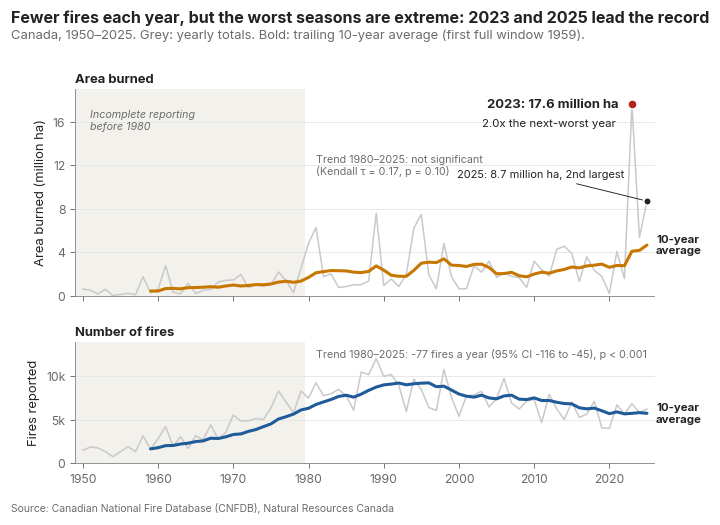

{'record_year': 2023,
 'record_mha': np.float64(17.606546667790017),
 'ratio': np.float64(2.022055268294876),
 'area_80s90s_mha': np.float64(2.780531480049223),
 'area_last20_mha': np.float64(3.650404568234849),
 'fires_80s90s': np.float64(8573.35),
 'fires_last20': np.float64(6277.95),
 'peak_fire_year_smoothed': 1996,
 'runner_year': 2025,
 'runner_mha': np.float64(8.707252934108455),
 'area_trend': {'tau': np.float64(0.16908212560386474),
  'p': np.float64(0.09753432244412781),
  'slope': np.float64(34978.854282272616),
  'lo': np.float64(-6511.1214676725485),
  'hi': np.float64(80662.75593929074),
  'years': '1980–2025'},
 'fire_trend': {'tau': np.float64(-0.43188405797101453),
  'p': np.float64(2.3135076441665827e-05),
  'slope': np.float64(-77.22222222222223),
  'lo': np.float64(-115.76666666666667),
  'hi': np.float64(-44.77272727272727),
  'years': '1980–2025'}}

In [7]:
fig, facts = fig1_trend(df)
st.save(fig, "fig1_trend")
plt.show()
facts

### Figure 2: When the land burns
**Point this figure supports:** Burning is concentrated in May–August (97% of dated area). 2023 started early, with the largest May in 76 years (6.5 Mha).

In [8]:
def fig2_season_heatmap(df):
    from matplotlib.colors import PowerNorm
    months = list(range(3, 11))  # Mar-Oct hold 99.8% of dated area burned
    mnames = ["Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
    dated = df[df.MONTH > 0]
    grid = (dated.pivot_table(index="MONTH", columns="YEAR", values="SIZE_HA", aggfunc="sum")
            .reindex(index=months, columns=range(fd.FIRST_YEAR, fd.LAST_YEAR + 1)).fillna(0))
    share_shown = dated[dated.MONTH.isin(months)].SIZE_HA.sum() / dated.SIZE_HA.sum()

    fig, ax = plt.subplots(figsize=(st.TEXT_WIDTH, 3.05))
    vals = grid.to_numpy().copy()
    vals[vals < 100] = np.nan                       # <100 ha in a month = "little or none"
    cmap = sns.color_palette(st.FIRE_CMAP, as_cmap=True).copy()
    cmap.set_bad("white")                           # blank = little or no burning
    x = np.arange(fd.FIRST_YEAR, fd.LAST_YEAR + 2) - 0.5
    yy = np.arange(len(months) + 1) - 0.5
    vmax = np.nanmax(vals)
    mesh = ax.pcolormesh(x, yy, vals, cmap=cmap, norm=PowerNorm(0.5, vmin=0, vmax=vmax),
                         edgecolors="white", linewidth=0.35)
    ax.set_yticks(range(len(months)), mnames)
    ax.invert_yaxis()
    ax.set_xticks(range(1950, 2030, 10))
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    # focus: outline 2023 and call out its record May
    ax.add_patch(plt.Rectangle((2022.5, -0.5), 1, len(months), fill=False, ec=st.INK, lw=1.1))
    may23 = grid.loc[5, 2023]
    may_rank = int(grid.loc[5].rank(ascending=False)[2023])
    ax.annotate(f"May 2023: {may23 / 1e6:.1f} million ha,\nthe largest May on record",
                xy=(2023, 2), xytext=(2014, -1.25), fontsize=7.5, color=st.INK,
                ha="right", va="center", fontweight="semibold", annotation_clip=False,
                arrowprops=dict(arrowstyle="-", color=st.INK, lw=0.7, shrinkB=0,
                                connectionstyle="angle,angleA=0,angleB=90,rad=0"))

    fig.subplots_adjust(top=0.68, left=0.06, right=0.995, bottom=0.11)
    cax = fig.add_axes([0.075, 0.755, 0.33, 0.03])
    cb = fig.colorbar(mesh, cax=cax, orientation="horizontal")
    cb.outline.set_visible(False)
    ticks = [0, 0.1e6, 0.5e6, 1e6, 2e6, 4e6, 6e6]
    cb.set_ticks(ticks, labels=["0", "0.1", "0.5", "1", "2", "4", "6M ha"])
    cb.ax.tick_params(labelsize=6.8, length=0, pad=2)
    cb.ax.set_title("Area burned in the month (square-root scale)", fontsize=6.8,
                    color=st.MUTED, loc="left", pad=3)
    st.headline(fig, "Canada burns in a narrow early-summer window; 2023 ignited it early",
                "Hectares burned per month, 1950–2025. Blank cells: under 100 ha. Reporting is incomplete before 1980.", y=0.995)
    st.source_note(fig)
    peak = grid.sum(axis=1)
    facts = dict(share_mar_oct=share_shown, may23_mha=may23 / 1e6, may23_rank=may_rank,
                 share_may_aug=peak.loc[5:8].sum() / peak.sum(),
                 jun_jul_share=peak.loc[6:7].sum() / peak.sum())
    return fig, facts

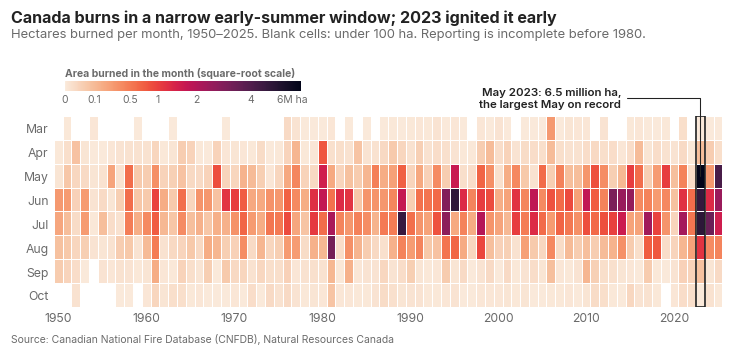

{'share_mar_oct': np.float64(0.9985247765878931),
 'may23_mha': np.float64(6.453021884680314),
 'may23_rank': 1,
 'share_may_aug': np.float64(0.974969560233395),
 'jun_jul_share': np.float64(0.7041168011056581)}

In [9]:
fig, facts = fig2_season_heatmap(df)
st.save(fig, "fig2_season_heatmap")
plt.show()
facts

### Figure 3: 2023 by province and territory
**Point this figure supports:** Five jurisdictions each burned over 1.5 Mha in 2023 (93% of the year); Quebec and the NWT alone made up half.

In [10]:
def fig3_treemap_2023(df):
    import squarify
    d = df[df.YEAR == 2023]
    by = d.groupby("province", observed=True).SIZE_HA.sum().sort_values(ascending=False)
    by = by[by > 0]
    keep = by[by >= 1e6]
    rest = by[by < 1e6]
    tiles = pd.concat([keep, pd.Series({"Other 7": rest.sum()})])
    total = by.sum()
    top4 = by[by >= 1.5e6]                       # focus: every jurisdiction over 1.5 Mha
    top2 = by.head(2)

    W, H = 100, 36
    fig, ax = plt.subplots(figsize=(st.TEXT_WIDTH, 2.45))
    rects = squarify.squarify(squarify.normalize_sizes(tiles.values, W, H), 0, 0, W, H)
    for r, (name, val) in zip(rects, tiles.items()):
        focal = name in top4.index
        fc = st.EMBER if focal else ("#E7E2DA" if name == "Other 7" else "#CFC7BC")
        tc = "white" if focal else st.INK
        ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["dx"], r["dy"], fc=fc, ec="white", lw=2.2))
        label = name if name != "Other 7" else "Others*"
        narrow = r["dx"] < 15
        if narrow:
            label = label.replace(" ", "\n")
        ax.text(r["x"] + 1.2, r["y"] + r["dy"] - 1.8, label, ha="left", va="top",
                fontsize=8.5 if focal else 7.5, fontweight="bold", color=tc, linespacing=1.15)
        ax.text(r["x"] + 1.2, r["y"] + r["dy"] - (9.6 if narrow else 6.0),
                f"{val / 1e6:.1f} Mha · {val / total:.0%}",
                ha="left", va="top", fontsize=7.5 if focal else 7, color=tc)
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.axis("off")
    fig.subplots_adjust(top=0.79, bottom=0.08, left=0, right=1)
    st.headline(fig, f"2023 burned in five jurisdictions at once; {top2.index[0]} and the NWT "
                f"made up half",
                f"Area burned in 2023 ({total / 1e6:.1f} million ha) by where the fires burned. "
                "Tile area = hectares. Red: over 1.5 million ha.", y=0.995)
    st.source_note(fig, st.SOURCE + ".  *" + ", ".join(rest.index) + ".")
    facts = dict(total_mha=total / 1e6, focal=list(top4.index), focal_share=top4.sum() / total,
                 top2_share=top2.sum() / total, by_province_mha=(by / 1e6).round(2).to_dict(),
                 regions_over_1mha=int((by >= 1e6).sum()))
    return fig, facts

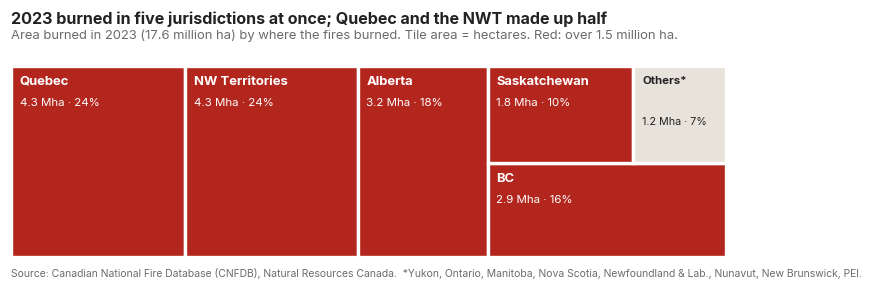

{'total_mha': np.float64(17.606217167790014),
 'focal': ['Quebec', 'NW Territories', 'Alberta', 'BC', 'Saskatchewan'],
 'focal_share': np.float64(0.9345641279348968),
 'top2_share': np.float64(0.48506948138025724),
 'by_province_mha': {'Quebec': 4.29,
  'NW Territories': 4.25,
  'Alberta': 3.2,
  'BC': 2.9,
  'Saskatchewan': 1.81,
  'Yukon': 0.47,
  'Ontario': 0.44,
  'Manitoba': 0.2,
  'Nova Scotia': 0.03,
  'Newfoundland & Lab.': 0.02,
  'Nunavut': 0.0,
  'New Brunswick': 0.0,
  'PEI': 0.0},
 'regions_over_1mha': 5}

In [11]:
fig, facts = fig3_treemap_2023(df)
st.save(fig, "fig3_treemap_2023")
plt.show()
facts

## 4. Q2: How do lightning and human fires differ?

### Figure 4: Share of fires vs share of area
**Point this figure supports:** People start 54% of fires but cause only 12% of the area burned; lightning starts 44% but burns 84%.

In [12]:
def fig4_waffle_cause(df):
    counts = df.cause.value_counts().reindex(fd.CAUSE_ORDER)
    area = df.groupby("cause", observed=True).SIZE_HA.sum().reindex(fd.CAUSE_ORDER)
    c_sq, a_sq = _largest_remainder(counts), _largest_remainder(area)
    colors = [st.CAUSE_COLORS[c] for c in fd.CAUSE_ORDER]

    fig = plt.figure(figsize=(st.TEXT_WIDTH, 2.7))
    axes = [fig.add_axes([0.0, 0.1, 0.27, 0.62]), fig.add_axes([0.5, 0.1, 0.27, 0.62])]
    for ax, title, sq in ((axes[0], "Share of fires started", c_sq),
                          (axes[1], "Share of area burned", a_sq)):
        _waffle(ax, sq, colors)
        ax.text(0, 10.35, title, fontsize=8.5, fontweight="bold", color=st.INK, va="bottom")
        y = 9.6
        for cause, k in zip(fd.CAUSE_ORDER, sq):
            ax.add_patch(plt.Rectangle((10.6, y - 2.55), 0.62, 0.62, fc=st.CAUSE_COLORS[cause],
                                       ec="none", clip_on=False))
            ax.text(10.6, y, f"{k}%", fontsize=14, fontweight="bold", color=st.INK,
                    va="top", ha="left")
            ax.text(11.45, y - 2.0, cause, fontsize=7.5, color=st.MUTED, va="top", ha="left")
            y -= 3.4
    st.headline(fig, "People start most fires, but lightning burns most of the land",
                "Each square is 1% of all fires (left) or of all hectares burned (right), 1950–2025.",
                y=0.995)
    st.source_note(fig, st.SOURCE + ". Squares rounded to sum to exactly 100.")
    facts = dict(fire_share=dict(zip(fd.CAUSE_ORDER, (counts / counts.sum()).round(3))),
                 area_share=dict(zip(fd.CAUSE_ORDER, (area / area.sum()).round(3))),
                 mean_size=dict(zip(fd.CAUSE_ORDER, (area / counts).round(1))))
    return fig, facts

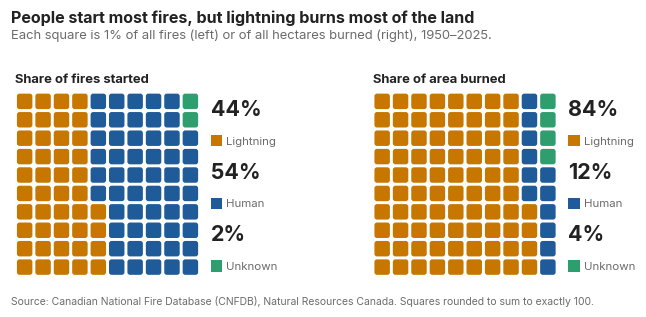

{'fire_share': {'Lightning': 0.435, 'Human': 0.54, 'Unknown': 0.025},
 'area_share': {'Lightning': 0.844, 'Human': 0.115, 'Unknown': 0.041},
 'mean_size': {'Lightning': 719.9, 'Human': 79.1, 'Unknown': 613.3}}

In [13]:
fig, facts = fig4_waffle_cause(df)
st.save(fig, "fig4_waffle_cause")
plt.show()
facts

### Figure 5: Two fire seasons
**Point this figure supports:** Human fires peak in May (42% in March–May); 90% of lightning fires start in June–August.

In [14]:
def fig5_radar_season(df):
    dated = df[df.MONTH > 0]
    share = (pd.crosstab(dated.MONTH, dated.cause, normalize="columns")
             .reindex(range(1, 13)).fillna(0))
    labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    theta = np.linspace(0, 2 * np.pi, 12, endpoint=False)

    fig = plt.figure(figsize=(st.TEXT_WIDTH, 3.6))
    ax = fig.add_axes([0.05, 0.11, 0.46, 0.66], projection="polar")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    rmax = 0.40
    for r in (0.1, 0.2, 0.3, 0.4):
        ax.plot(np.linspace(0, 2 * np.pi, 200), [r] * 200, color=st.GRID, lw=0.7, zorder=0)
    ax.text(np.deg2rad(-5), 0.1, "10%", fontsize=6.5, color=st.MUTED, ha="right")
    ax.text(np.deg2rad(-5), 0.2, "20%", fontsize=6.5, color=st.MUTED, ha="right")
    ax.text(np.deg2rad(-5), 0.3, "30%", fontsize=6.5, color=st.MUTED, ha="right")
    ax.grid(False)
    ax.spines["polar"].set_visible(False)
    ax.set_yticks([])
    ax.set_xticks(theta, labels, fontsize=7.5, color=st.MUTED)
    ax.set_ylim(0, rmax)
    for cause, lw, z in (("Human", 2.2, 3), ("Lightning", 2.2, 3)):
        v = share[cause].to_numpy()
        t = np.append(theta, theta[0])
        vv = np.append(v, v[0])             # close the loop (L11 p.6)
        ax.plot(t, vv, color=st.CAUSE_COLORS[cause], lw=lw, zorder=z)   # lines only: a filled
        ax.scatter(theta, v, s=22, color=st.CAUSE_COLORS[cause], edgecolor="white", linewidth=1.0,
                   zorder=z + 1)                                     # area would grow with r²
    # direct labels at each peak
    hp, lp = share["Human"].idxmax(), share["Lightning"].idxmax()
    ax.annotate(f"Human\npeaks in May\n({share.loc[hp, 'Human']:.0%})", xy=(theta[hp - 1], share.loc[hp, "Human"]),
                xytext=(np.deg2rad(22), 0.25), fontsize=7.5, color=st.INK, fontweight="bold",
                ha="left", arrowprops=dict(arrowstyle="-", color=st.HUMAN, lw=0.7))
    ax.annotate(f"Lightning\npeaks in July\n({share.loc[lp, 'Lightning']:.0%})",
                xy=(theta[lp - 1], share.loc[lp, "Lightning"]), xytext=(np.deg2rad(238), 0.27),
                fontsize=7.5, color=st.INK, fontweight="bold", ha="right",
                arrowprops=dict(arrowstyle="-", color=st.LIGHTNING, lw=0.7))

    # side panel: the reading guide + the 3 numbers that matter
    spring_h = share.loc[3:5, "Human"].sum()
    summer_l = share.loc[6:8, "Lightning"].sum()
    tx = 0.6
    fig.text(tx, 0.70, "How to read", fontsize=8, fontweight="bold", color=st.INK)
    fig.text(tx, 0.67, "Each spoke is a month. Distance from the centre is\nthat month's share "
             "of the year's fires for each cause,\nso the two shapes compare timing, not volume.",
             fontsize=7.2, color=st.MUTED, va="top", linespacing=1.4)
    kx = tx                                                  # legend key (two series)
    for c, lab in ((st.LIGHTNING, "Lightning"), (st.HUMAN, "Human")):
        fig.add_artist(plt.Line2D([kx, kx + 0.03], [0.78, 0.78], color=c, lw=2.2,
                                  transform=fig.transFigure))
        fig.text(kx + 0.037, 0.78, lab, fontsize=7.8, color=st.INK, va="center")
        kx += 0.14
    fig.add_artist(plt.Rectangle((tx - 0.025, 0.478), 0.014, 0.028, fc=st.HUMAN, ec="none",
                                 transform=fig.transFigure))
    fig.add_artist(plt.Rectangle((tx - 0.025, 0.308), 0.014, 0.028, fc=st.LIGHTNING, ec="none",
                                 transform=fig.transFigure))
    fig.text(tx, 0.47, f"{spring_h:.0%}", fontsize=20, fontweight="bold", color=st.INK)
    fig.text(tx + 0.13, 0.475, "of human-caused fires start\nin spring (March–May)",
             fontsize=7.5, color=st.INK, linespacing=1.3)
    fig.text(tx, 0.30, f"{summer_l:.0%}", fontsize=20, fontweight="bold", color=st.INK)
    fig.text(tx + 0.13, 0.305, "of lightning fires start in\nsummer (June–August)",
             fontsize=7.5, color=st.INK, linespacing=1.3)
    st.headline(fig, "Two fire seasons: people burn in spring, lightning in summer",
                "Share of each cause's fires by month of discovery, 1950–2025 (dated records; Unknown cause omitted).",
                y=0.995)
    st.source_note(fig)
    facts = dict(human_peak_month=int(hp), lightning_peak_month=int(lp),
                 human_mar_may=spring_h, lightning_jun_aug=summer_l)
    return fig, facts

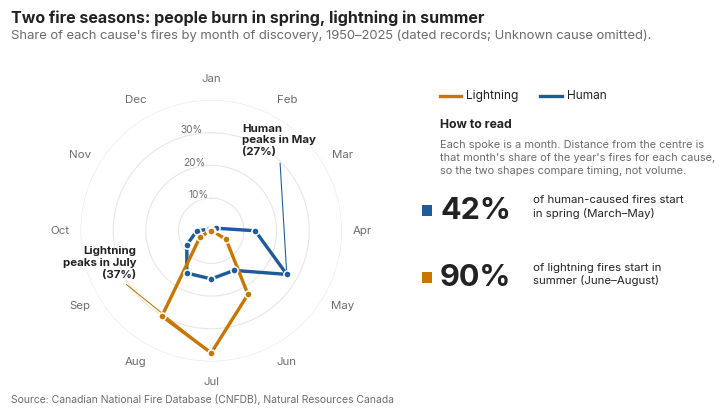

{'human_peak_month': 5,
 'lightning_peak_month': 7,
 'human_mar_may': np.float64(0.4174435766939395),
 'lightning_jun_aug': np.float64(0.9007085653346459)}

In [15]:
fig, facts = fig5_radar_season(df)
st.save(fig, "fig5_radar_season")
plt.show()
facts

### Figure 6: Where each cause burns
**Point this figure supports:** Lightning burns 74–96% of the area in every province or territory with over 10 Mha burned; the Maritimes together burned under 0.2 Mha.

In [16]:
def fig6_region_cause(df):
    pv = (df.pivot_table(index="province", columns="cause", values="SIZE_HA", aggfunc="sum",
                         observed=True).reindex(columns=fd.CAUSE_ORDER).fillna(0))
    pv = pv[pv.sum(axis=1) > 0]
    pv = pv.loc[pv.sum(axis=1).sort_values().index]          # ranked, largest on top
    total = pv.sum(axis=1)

    fig, ax = plt.subplots(figsize=(st.TEXT_WIDTH, 3.9))
    left = np.zeros(len(pv))
    for cause in fd.CAUSE_ORDER:
        ax.barh(pv.index, pv[cause], left=left, color=st.CAUSE_COLORS[cause], height=0.68,
                edgecolor="white", linewidth=0.8, label=cause)
        left += pv[cause].to_numpy()
    for i, (name, tot) in enumerate(total.items()):
        lshare = pv.loc[name, "Lightning"] / tot if tot else 0
        lab = f"{tot / 1e6:.1f} Mha" if tot >= 0.1e6 else "<0.1 Mha"
        t = ax.text(tot + 0.35e6, i, lab, va="center", fontsize=7.5, color=st.INK,
                    fontweight="semibold")
        if tot > 1e6:
            ax.annotate(f"  {lshare:.0%} lightning", xycoords=t, xy=(1, 0.5), va="center",
                        fontsize=6.8, color=st.MUTED)
    ax.set_xlim(0, total.max() * 1.18)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(st.mha))
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_xlabel("Area burned, 1950–2025 (million ha)")
    ax.tick_params(axis="y", length=0, labelsize=8, labelcolor=st.INK)
    ax.spines["left"].set_visible(False)
    # legend as direct colour key above the plot
    x0 = 0.0
    for cause in fd.CAUSE_ORDER:
        ax.text(x0, 1.015, "■ ", transform=ax.transAxes, color=st.CAUSE_COLORS[cause], fontsize=10,
                va="bottom")
        ax.text(x0 + 0.03, 1.02, cause, transform=ax.transAxes, color=st.INK, fontsize=8, va="bottom")
        x0 += 0.13
    fig.subplots_adjust(top=0.82, bottom=0.12, left=0.2, right=0.98)
    big = total[total > 10e6].index
    lshare = pv.loc[big, "Lightning"] / total[big]
    st.headline(fig, "Lightning burns most of the land in every major fire region; the Maritimes barely burn",
                "Total area burned 1950–2025 by the province or territory where the fire burned, and by cause. "
                "Ranked; bars start at zero.", y=0.995)
    st.source_note(fig, st.SOURCE + ". Records start 1950–60 for most agencies, New Brunswick 1980, PEI 2018.")
    nt = pv.loc["NW Territories"]
    facts = dict(top=total.idxmax(), top_mha=total.max() / 1e6,
                 nt_lightning_share=nt["Lightning"] / nt.sum(),
                 east_mha=total.reindex(["Nova Scotia", "New Brunswick", "PEI"]).sum() / 1e6,
                 lightning_share_big=lshare.round(3).to_dict())
    return fig, facts

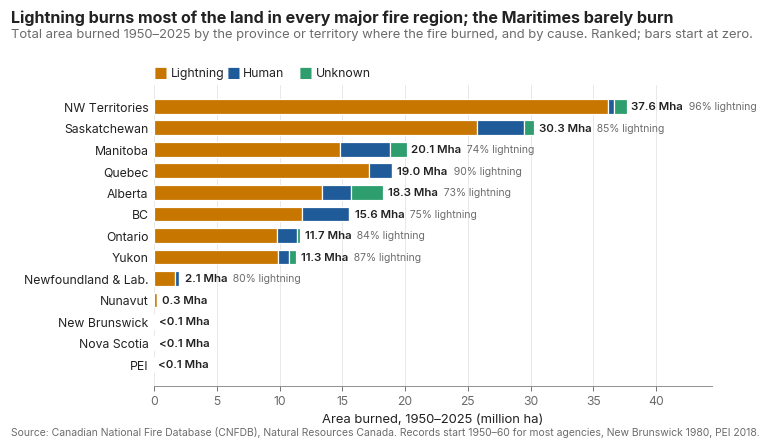

{'top': 'NW Territories',
 'top_mha': np.float64(37.64652770653735),
 'nt_lightning_share': np.float64(0.9598676210052504),
 'east_mha': np.float64(0.15545077951758343),
 'lightning_share_big': {'Yukon': 0.869,
  'Ontario': 0.84,
  'BC': 0.755,
  'Alberta': 0.735,
  'Quebec': 0.899,
  'Manitoba': 0.737,
  'Saskatchewan': 0.848,
  'NW Territories': 0.96}}

In [17]:
fig, facts = fig6_region_cause(df)
st.save(fig, "fig6_region_cause")
plt.show()
facts

### Figure 7: Where fires start, by cause
**Point this figure supports:** Lightning ignitions spread across the remote boreal interior; human ignitions trace roads, rivers and the populated south.

In [18]:
def fig10_ignition_maps(df):
    from pyproj import Transformer
    prov, _ = _load_geo()
    tr = Transformer.from_crs(4326, prov.crs, always_xy=True)
    x, y = tr.transform(df.LONGITUDE.to_numpy(), df.LATITUDE.to_numpy())
    pts = df.assign(x=x, y=y)
    fig, axes = plt.subplots(1, 2, figsize=(st.TEXT_WIDTH, 3.15))
    for ax, cause in zip(axes, ["Lightning", "Human"]):
        _base_map(ax, prov)
        p = pts[pts.cause == cause]
        ax.scatter(p.x, p.y, s=0.25, color=st.CAUSE_COLORS[cause], alpha=0.25, linewidths=0,
                   rasterized=True, zorder=2)
        prov.boundary.plot(ax=ax, color="white", linewidth=0.4, zorder=3)
        ax.set_title(f"      {cause}  ·  {len(p):,} fires", fontsize=8.5, fontweight="bold",
                     color=st.INK, loc="left", pad=2)
        ax.add_patch(plt.Rectangle((0.0, 1.052), 0.022, 0.034, fc=st.CAUSE_COLORS[cause], ec="none",
                                   transform=ax.transAxes, clip_on=False))
    lat = df.groupby("cause", observed=True).LATITUDE.median()
    fig.subplots_adjust(top=0.8, bottom=0.04, left=0.0, right=1.0, wspace=0.02)
    st.headline(fig, "Lightning strikes the remote north; people start fires where they live",
                "Every fire start, 1950–2025, by cause. Blank southern Prairies: farmland outside agency fire reporting.", y=0.995)
    st.source_note(fig, "Source: CNFDB point data, NRCan; provinces: Natural Earth.")
    facts = dict(median_lat=lat.round(2).to_dict())
    return fig, facts

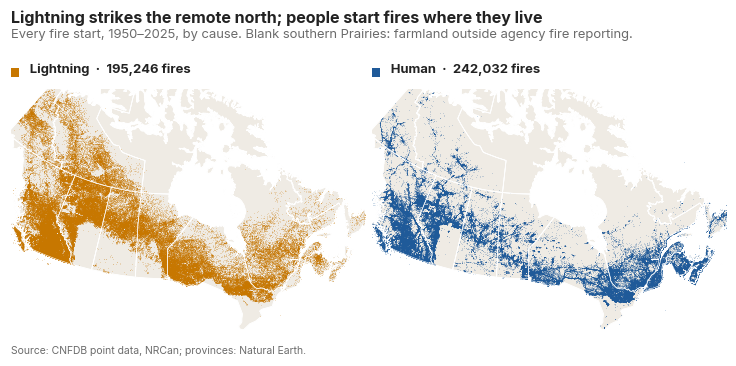

{'median_lat': {'Lightning': 52.23, 'Human': 50.21, 'Unknown': 51.73}}

In [19]:
fig, facts = fig10_ignition_maps(df)
st.save(fig, "fig10_ignition_maps")
plt.show()
facts

## 5. Q3: Do a few huge fires dominate, and has typical size changed?

### Figure 8: A few huge fires do almost all the burning
**Point this figure supports:** Fires of 200 ha or more are 5.3% of fires with a recorded size but 98.9% of the area; the largest 1% burned 83%.

In [20]:
def fig7_size_histogram(df):
    s = df.loc[df.SIZE_HA > 0, ["SIZE_HA"]].copy()
    edges = 200.0 * 10.0 ** (np.arange(-18, 18) / 4)     # 4 bins per decade, aligned so 200 ha is an edge
    s["bin"] = pd.cut(s.SIZE_HA, edges, right=False)
    g = s.groupby("bin", observed=False).SIZE_HA.agg(["size", "sum"])
    cnt_pct = g["size"] / g["size"].sum() * 100
    area_pct = g["sum"] / g["sum"].sum() * 100
    left, width = edges[:-1], np.diff(edges)

    big = 200.0                                          # threshold used in fire statistics
    sized = s.SIZE_HA                                    # denominator: fires with a recorded size > 0
    share_n = (sized >= big).mean()
    share_a = sized[sized >= big].sum() / sized.sum()
    under1 = (sized < 1).mean()
    sorted_sz = sized.sort_values(ascending=False)
    top1 = sorted_sz.head(len(sorted_sz) // 100).sum() / sorted_sz.sum()

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(st.TEXT_WIDTH, 3.9), sharex=True,
                                 gridspec_kw={"hspace": 0.08})
    is_big = left >= big * 0.999
    a1.bar(left, cnt_pct, width=width * 0.9, align="edge",
           color=np.where(is_big, st.EMBER, NEUTRAL))
    a2.bar(left, -area_pct, width=width * 0.9, align="edge",
           color=np.where(is_big, st.EMBER, NEUTRAL))
    for ax in (a1, a2):
        ax.set_xscale("log")
        ax.axvline(big, color=st.INK, lw=0.7, ls=(0, (1, 2)))
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)
    a1.set_ylabel("% of fires")
    a2.set_ylabel("% of area burned")
    a2.yaxis.set_major_locator(mticker.MultipleLocator(4))
    a2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
    a1.yaxis.set_major_locator(mticker.MultipleLocator(10))
    a1.spines["bottom"].set_visible(False)
    a1.tick_params(axis="x", length=0)
    a2.spines["bottom"].set_visible(False)
    a2.spines["top"].set_visible(True)
    a2.spines["top"].set_color("#8A8A8A")
    a2.xaxis.tick_bottom()
    a2.set_xlim(0.006, 4e6)
    a2.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda v, _: {0.01: "0.01 ha", 1: "1 ha", 100: "100 ha", 1e4: "10,000 ha", 1e6: "1M ha"}.get(round(v, 2), "")))
    a2.set_xticks([0.01, 0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6])
    a2.set_xlabel("Final fire size (log scale)")

    a1.text(big * 1.25, a1.get_ylim()[1] * 0.92,
            f"Fires of {big:.0f} ha or more:\n{share_n:.1%} of fires…", color=st.INK,
            fontsize=8, fontweight="bold", va="top")
    a2.text(big / 1.25, a2.get_ylim()[0] * 0.85, f"…but {share_a:.1%} of\nthe area burned",
            color=st.INK, fontsize=8, fontweight="bold", va="bottom", ha="right")
    a1.text(1.4, a1.get_ylim()[1] * 0.6,
            f"{under1:.0%} of fires are recorded\nunder 1 ha",
            color="#4A4A4A", fontsize=7.5, va="top")
    a1.text(0.13, a1.get_ylim()[1] * 0.98, "Spike: small fires are\noften logged as 0.1 ha",
            color=st.MUTED, fontsize=6.6, va="top", style="italic")
    a2.text(0.012, a2.get_ylim()[0] * 0.45, f"The largest 1% of fires\nburned {top1:.0%} of the area",
            color=st.INK, fontsize=7.5, va="center", ha="left", fontweight="semibold")
    fig.subplots_adjust(top=0.84, bottom=0.12, left=0.1, right=0.99)
    st.headline(fig, f"A few huge fires do almost all the burning",
                f"Fires with a recorded size, 1950–2025 (n = {len(sized):,}): share of fires (top) and "
                "share of area burned (bottom) in each size band.", y=0.995)
    st.source_note(fig)
    facts = dict(share_fires_ge200=share_n, share_area_ge200=share_a, top1pct_area=top1,
                 median_ha=sized.median(), share_under_1ha=under1, n_sized=len(sized),
                 n_zero=int((df.SIZE_HA == 0).sum()))
    return fig, facts

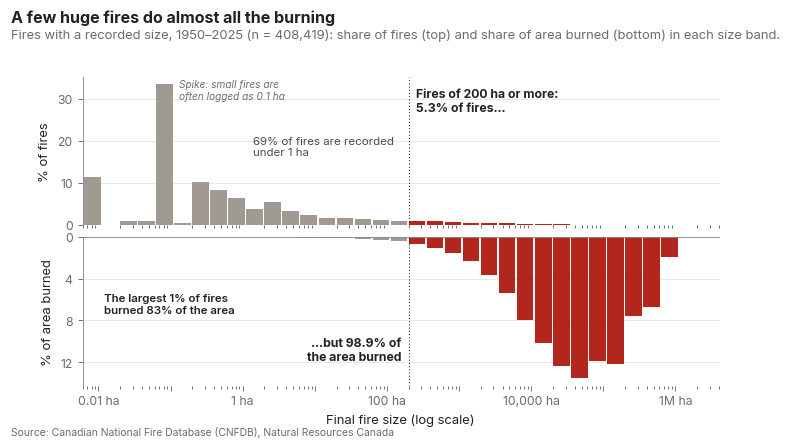

{'share_fires_ge200': np.float64(0.05291134839466333),
 'share_area_ge200': np.float64(0.989005337508843),
 'top1pct_area': np.float64(0.8309258561064924),
 'median_ha': np.float64(0.2),
 'share_under_1ha': np.float64(0.6937116049938911),
 'n_sized': 408419,
 'n_zero': 40028}

In [21]:
fig, facts = fig7_size_histogram(df)
st.save(fig, "fig7_size_histogram")
plt.show()
facts

### Figure 9: Escaped lightning fires have grown since 1980
**Point this figure supports:** The yearly median size of lightning fires over 1 ha rose over 1980–2025 (Spearman ρ = 0.68, p < 0.001; 0.66 without 2023); human fires show no significant change (ρ = 0.28, p = 0.06).

In [22]:
def fig8_boxen_decade(df):
    d = df[(df.SIZE_HA >= 1) & df.cause.isin(["Lightning", "Human"])].copy()   # fires that escaped
    d["cause"] = d["cause"].cat.remove_unused_categories()
    d["dec"] = d.decade.astype(str) + "s"
    order = [f"{y}s" for y in range(1950, 2030, 10)]
    fig, ax = plt.subplots(figsize=(st.TEXT_WIDTH, 3.3))
    sns.boxenplot(data=d, x="dec", y="SIZE_HA", hue="cause", order=order,
                  hue_order=["Lightning", "Human"], palette=st.CAUSE_COLORS, log_scale=True,
                  k_depth=4, width=0.78, gap=0.12, linewidth=0.5, linecolor="white",
                  flier_kws=dict(s=1.2, alpha=0.35, linewidth=0), ax=ax, legend=False)
    ax.axvspan(-0.5, 2.5, color="#F3F1EC", zorder=0, lw=0)
    ax.text(-0.42, 2.4e6, "Incomplete\nreporting", fontsize=6.8, color=st.MUTED, va="top", style="italic")
    med = d.groupby(["dec", "cause"], observed=True).SIZE_HA.median().unstack()
    p99 = d.groupby(["dec", "cause"], observed=True).SIZE_HA.quantile(0.99).unstack()
    ax.set_ylim(0.8, 3e6)
    ax.set_xlabel("")
    ax.set_ylabel("Final fire size (ha, log scale)")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(
        lambda v, _: {1: "1", 10: "10", 100: "100", 1e3: "1k", 1e4: "10k", 1e5: "100k", 1e6: "1M"}.get(round(v, 2), "")))
    ax.yaxis.set_minor_locator(mticker.NullLocator())
    for i, dec in enumerate(order):                     # median labels, both causes
        for dx, cause in ((-0.2, "Lightning"), (0.2, "Human")):
            m = med.loc[dec, cause]
            ax.text(i + dx, m, f"{m:.0f}", ha="center", va="center", fontsize=6.3, color="white",
                    fontweight="bold", bbox=dict(boxstyle="round,pad=0.15",
                                                 fc=st.CAUSE_COLORS[cause], ec="none"))
    ax.set_xticks(range(len(order)), order[:-1] + ["2020s\n(2020–25)"])
    # trend test on yearly medians, 1980 on (complete reporting)
    rec = d[d.YEAR >= fd.FULL_REPORTING_FROM]
    ym = rec.groupby(["YEAR", "cause"], observed=True).SIZE_HA.median().unstack()
    rho = {c: stats.spearmanr(ym.index, ym[c]) for c in ("Lightning", "Human")}
    no23 = ym.drop(2023)
    rho_l_no23 = stats.spearmanr(no23.index, no23["Lightning"])[0]
    ax.text(0.995, 0.97, f"Yearly median vs year, 1980–2025 (Spearman):\n"
            f"lightning ρ = {rho['Lightning'][0]:.2f}, {_p(rho['Lightning'][1])} "
            f"({rho_l_no23:.2f} without 2023)\n"
            f"human ρ = {rho['Human'][0]:.2f}, {_p(rho['Human'][1])}",
            transform=ax.transAxes, ha="right", va="top", fontsize=6.8, color=st.INK,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=st.GRID, lw=0.6))
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", length=0, labelcolor=st.INK)
    ax.text(0.0, 1.03, "■", transform=ax.transAxes, color=st.LIGHTNING, fontsize=10, va="bottom")
    ax.text(0.025, 1.035, "Lightning", transform=ax.transAxes, fontsize=8, va="bottom")
    ax.text(0.14, 1.03, "■", transform=ax.transAxes, color=st.HUMAN, fontsize=10, va="bottom")
    ax.text(0.165, 1.035, "Human", transform=ax.transAxes, fontsize=8, va="bottom")
    ax.text(0.26, 1.035, "Widest box = middle 50% of fires; each narrower box adds the next tail.",
            transform=ax.transAxes, fontsize=7, color=st.MUTED, va="bottom")
    fig.subplots_adjust(top=0.8, bottom=0.08, left=0.1, right=0.99)
    st.headline(fig, "Since 1980 the typical escaped lightning fire has grown; human fires have not",
                "Size of fires that grew past 1 ha, by decade and cause (boxen plot). "
                "Labels: median size (ha).",
                y=0.995)
    st.source_note(fig)
    n = d.groupby(["dec", "cause"], observed=True).size().unstack()
    facts = dict(median=med.round(2).to_dict(), p99=p99.round(0).to_dict(), n=n.to_dict(),
                 rho_lightning=rho["Lightning"][0], p_lightning=rho["Lightning"][1],
                 rho_lightning_no2023=rho_l_no23, rho_human=rho["Human"][0], p_human=rho["Human"][1])
    return fig, facts

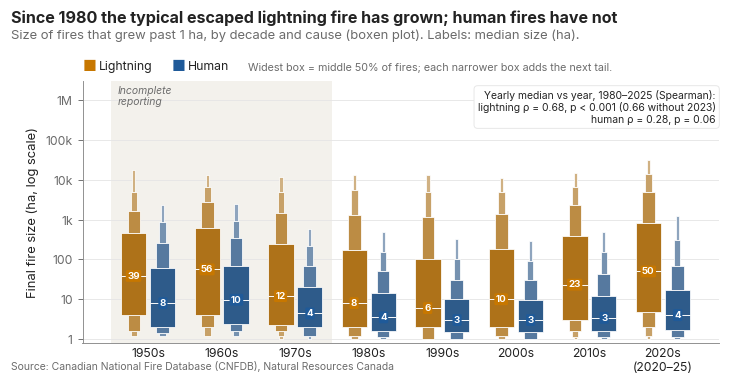

{'median': {'Lightning': {'1950s': 38.6,
   '1960s': 56.2,
   '1970s': 12.0,
   '1980s': 8.0,
   '1990s': 6.0,
   '2000s': 10.0,
   '2010s': 23.3,
   '2020s': 50.0},
  'Human': {'1950s': 8.0,
   '1960s': 9.7,
   '1970s': 4.4,
   '1980s': 3.5,
   '1990s': 3.0,
   '2000s': 3.0,
   '2010s': 3.4,
   '2020s': 4.0}},
 'p99': {'Lightning': {'1950s': 38316.0,
   '1960s': 33712.0,
   '1970s': 36282.0,
   '1980s': 47620.0,
   '1990s': 40042.0,
   '2000s': 31500.0,
   '2010s': 44205.0,
   '2020s': 87743.0},
  'Human': {'1950s': 12573.0,
   '1960s': 8655.0,
   '1970s': 2552.0,
   '1980s': 2465.0,
   '1990s': 2472.0,
   '2000s': 2310.0,
   '2010s': 3635.0,
   '2020s': 14761.0}},
 'n': {'Lightning': {'1950s': 1048,
   '1960s': 2773,
   '1970s': 6393,
   '1980s': 10755,
   '1990s': 12580,
   '2000s': 9502,
   '2010s': 10425,
   '2020s': 6870},
  'Human': {'1950s': 3115,
   '1960s': 4866,
   '1970s': 9368,
   '1980s': 13790,
   '1990s': 11366,
   '2000s': 8085,
   '2010s': 6381,
   '2020s': 3323}},
 '

In [23]:
fig, facts = fig8_boxen_decade(df)
st.save(fig, "fig8_boxen_decade")
plt.show()
facts

## 6. Q4: Where are the hotspots, and have they shifted?

### Figure 10: Half a century of burn scars
**Point this figure supports:** The boreal belt has not moved north (centre of burning 57.7–59.7°N in every decade), but mapped burning per year doubled in the 2020s and its centre moved about 370 km west.

In [24]:
def fig9_burn_scars(df):
    from matplotlib.colors import BoundaryNorm, ListedColormap
    import geopandas as gpd
    prov, scars = _load_geo()
    scars["dec"] = (scars.YEAR // 10) * 10
    decades = [1970, 1980, 1990, 2000, 2010, 2020]
    ramp = sns.color_palette("rocket_r", 9)[1:7]          # pale -> deep, six decades
    cen = scars_c = scar_centres(scars)
    fig, ax = plt.subplots(figsize=(st.TEXT_WIDTH, 4.9))
    _base_map(ax, prov, top=0.78)
    for dec, col in zip(decades, ramp):                    # oldest first, newest on top
        scars[scars.dec == dec].plot(ax=ax, color=col, linewidth=0, zorder=1 + dec / 1e4)
    prov.boundary.plot(ax=ax, color="white", linewidth=0.5, zorder=3)

    from matplotlib import patheffects as pe
    halo = [pe.withStroke(linewidth=2.2, foreground="white")]
    # centre of burning, decade by decade (the "has it shifted?" answer, drawn in place)
    ax.plot(cen.x, cen.y, color=st.INK, lw=0.9, zorder=5)
    for (dec, r), col in zip(cen.iterrows(), ramp):
        ax.scatter(r.x, r.y, s=34, color=col, edgecolor=st.INK, lw=0.8, zorder=6)
    first, last = cen.iloc[1], cen.iloc[-1]                # 1980s (complete) -> 2020s
    shift_km = (first.x - last.x) / 1000
    from matplotlib import patheffects as pe
    halo = [pe.withStroke(linewidth=2.2, foreground="white")]
    ax.annotate(f"Centre of burning\n{shift_km:.0f} km west\nsince the 1980s",
                xy=(first.x, first.y), xytext=(first.x + 0.36e6, first.y + 0.24e6), fontsize=7.2,
                color=st.INK, fontweight="semibold", ha="left", va="center", zorder=7,
                path_effects=halo, linespacing=1.15,
                arrowprops=dict(arrowstyle="-", color=st.INK, lw=0.6, shrinkB=5))
    for r, lab, ha, dx in ((first, "1980s", "left", 0.9e5), (last, "2020s", "right", -0.9e5)):
        ax.text(r.x + dx, r.y - 1.1e5, lab, fontsize=6.4, color=st.INK, ha=ha, va="center",
                fontweight="bold", zorder=7, path_effects=halo)

    # place names used in the title
    for code, label in (("NT", "Northwest\nTerritories"), ("QC", "Quebec"), ("BC", "BC"),
                        ("SK", "Sask."), ("AB", "Alberta"), ("ON", "Ontario")):
        pt = prov.loc[prov.postal == code].geometry.representative_point().iloc[0]
        dy = {"NT": -2.2e5, "QC": 2.8e5, "ON": 2.5e5}.get(code, 0)
        ax.text(pt.x, pt.y + dy, label, fontsize=6.6, color="#4A4A4A", ha="center", va="center",
                zorder=7, fontweight="semibold", linespacing=1.1, path_effects=halo)

    # scale bar: 500 km
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    sx, sy = x1 - 0.2 * (x1 - x0), y0 + 0.06 * (y1 - y0)
    ax.plot([sx, sx + 5e5], [sy, sy], color=st.INK, lw=1.4, solid_capstyle="butt", zorder=7)
    ax.text(sx + 2.5e5, sy + 0.012 * (y1 - y0), "500 km", fontsize=6.6, ha="center", va="bottom",
            color=st.INK, zorder=7)

    # inset: mapped area burned per year, by decade (normalised: the 2020s hold 5 seasons)
    ins = fig.add_axes([0.70, 0.60, 0.27, 0.17])
    ins.bar(range(len(cen)), cen.mha_per_year, color=ramp, width=0.72)
    for i, v in enumerate(cen.mha_per_year):
        ins.text(i, v + 0.15, f"{v:.1f}", ha="center", va="bottom", fontsize=6.4, color=st.INK)
    ins.set_xticks(range(len(cen)), ["70s", "80s", "90s", "00s", "10s", "20s"], fontsize=6.4)
    ins.set_yticks([])
    ins.spines[["left", "top", "right"]].set_visible(False)
    ins.tick_params(axis="x", length=0, pad=1)
    ins.set_ylim(0, cen.mha_per_year.max() * 1.25)
    ins.set_title("Mapped area burned per year (Mha)", fontsize=6.8, color=st.INK, loc="left",
                  fontweight="semibold", pad=3)
    ins.patch.set_alpha(0)

    # decade colour key (stepped, labelled)
    cax = fig.add_axes([0.03, 0.08, 0.34, 0.022])
    cmap = ListedColormap(ramp)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=BoundaryNorm(range(7), 6), cmap=cmap), cax=cax,
                      orientation="horizontal")
    cb.set_ticks([i + 0.5 for i in range(6)], labels=["1970s", "80s", "90s", "00s", "10s", "2020–24"])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, labelsize=6.8, pad=2)
    cb.ax.set_title("Decade the area burned (dots: centre of burning)", fontsize=7, color=st.MUTED,
                    loc="left", pad=3)

    lat = gpd.GeoSeries(gpd.points_from_xy(cen.x, cen.y), crs=prov.crs).to_crs(4326)
    fig.subplots_adjust(top=0.87, bottom=0.0, left=0.0, right=1.0)
    st.headline(fig, "The fire belt has not moved north; burning per year doubled and drifted west",
                f"Mapped perimeters of {len(scars):,} fires, 1972–2024, coloured by decade; small scars "
                "under ~1 km² simplified away (1% of area).", y=0.995)
    st.source_note(fig, "Source: CNFDB burned-area polygons, NRCan; provinces: Natural Earth. "
                   "Lambert conformal conic projection. 1970s polygons are the least complete.")
    facts = dict(n_scars=len(scars), mha_per_year=cen.mha_per_year.round(2).to_dict(),
                 centre_lat=dict(zip(cen.index, lat.y.round(2))),
                 centre_lon=dict(zip(cen.index, lat.x.round(2))), shift_km_west_80s_20s=shift_km)
    return fig, facts

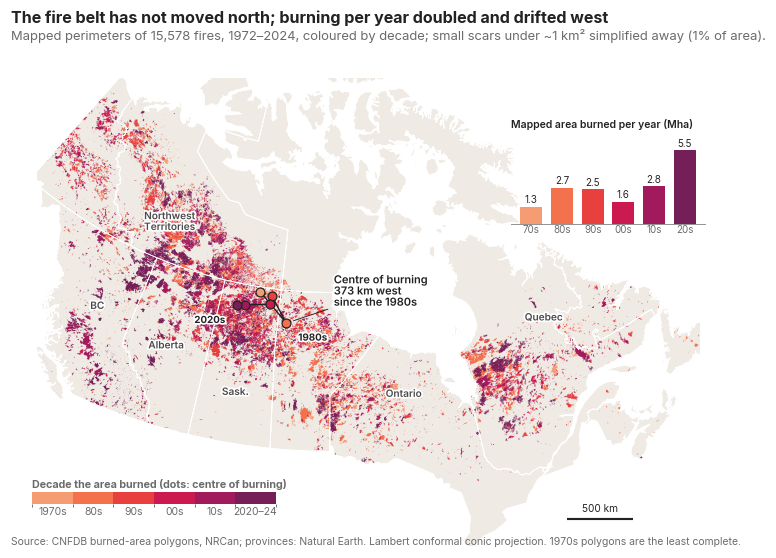

{'n_scars': 15578,
 'mha_per_year': {1970: 1.26,
  1980: 2.68,
  1990: 2.54,
  2000: 1.63,
  2010: 2.77,
  2020: 5.46},
 'centre_lat': {1970: 59.68,
  1980: 57.72,
  1990: 59.52,
  2000: 58.91,
  2010: 58.6,
  2020: 58.44},
 'centre_lon': {1970: -104.89,
  1980: -100.87,
  1990: -103.24,
  2000: -103.28,
  2010: -106.57,
  2020: -107.63},
 'shift_km_west_80s_20s': np.float64(373.02113479124534)}

In [25]:
fig, facts = fig9_burn_scars(df)
st.save(fig, "fig9_burn_scars")
plt.show()
facts

### Figure 11: Burning per unit of land
**Point this figure supports:** Per 1,000 km² of land, Saskatchewan burns hardest (935 ha a year), ahead of Manitoba and Alberta; the NWT, first in total area, is fourth.

In [26]:
def fig11_burn_rate_map(df):
    """Hectares burned per 1,000 km² of land per year, 1980-2025 (normalised choropleth)."""
    from matplotlib.colors import BoundaryNorm, ListedColormap
    prov, _ = _load_geo()
    rec = df[df.YEAR >= fd.FULL_REPORTING_FROM]
    years = fd.LAST_YEAR - fd.FULL_REPORTING_FROM + 1
    code = {v: k for k, v in fd.PROV_SHORT.items()}
    ha = rec.groupby("province", observed=True).SIZE_HA.sum().rename(index=code)
    prov = prov.set_index("postal")
    prov["rate"] = (ha.reindex(prov.index).fillna(0) / years) / (prov.geometry.area / 1e9)
    bins = [0, 50, 200, 400, 600, 1000]
    ramp = sns.color_palette("rocket_r", 8)[0:6:1][:len(bins) - 1]
    ramp[0] = "#F6EDE3"                                    # lowest class still visibly tinted
    cmap, norm = ListedColormap(ramp), BoundaryNorm(bins, len(bins) - 1)

    fig, ax = plt.subplots(figsize=(st.TEXT_WIDTH, 4.3))
    prov.plot(ax=ax, column="rate", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.7)
    ax.set_axis_off(); ax.set_aspect("equal")
    x0, y0, x1, y1 = prov.total_bounds
    ax.set_xlim(x0 + 0.02 * (x1 - x0), x1 - 0.04 * (x1 - x0))
    ax.set_ylim(y0, y0 + 0.78 * (y1 - y0))
    nudge = {"NU": (0, -6e5), "NT": (0, -2e5), "QC": (0, 2.5e5), "ON": (0, 2e5),
             "NS": (3.2e5, -1.4e5), "NB": (-1.5e5, 1.6e5), "PE": (2.4e5, 1.7e5)}
    for code_, r in prov.iterrows():
        pt = r.geometry.representative_point()
        dx, dy = nudge.get(code_, (0, 0))
        dark = r.rate >= 400
        ax.text(pt.x + dx, pt.y + dy, f"{code_}\n{r.rate:,.0f}", ha="center", va="center",
                fontsize=6.8 if code_ not in ("PE", "NS", "NB") else 6.0, linespacing=1.1,
                color="white" if dark else st.INK, fontweight="bold")
    cax = fig.add_axes([0.03, 0.09, 0.4, 0.022])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
    cb.set_ticks(bins, labels=[f"{b:,}" for b in bins])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=0, labelsize=6.8, pad=2)
    cb.ax.set_title("Hectares burned per 1,000 km² of land per year", fontsize=7, color=st.MUTED,
                    loc="left", pad=3)
    top = prov.rate.sort_values(ascending=False)
    fig.subplots_adjust(top=0.87, bottom=0.0, left=0.0, right=1.0)
    st.headline(fig, "Scaled by land area, Saskatchewan burns hardest and the NWT drops to fourth",
                f"Average yearly area burned per 1,000 km² of land, {fd.FULL_REPORTING_FROM}–{fd.LAST_YEAR}, "
                "by the province or territory where fires burned.", y=0.995)
    st.source_note(fig, "Source: CNFDB point data, NRCan; land area from Natural Earth provinces "
                   "(includes tundra and farmland with little fuel).")
    facts = dict(rate=top.round(0).to_dict())
    return fig, facts

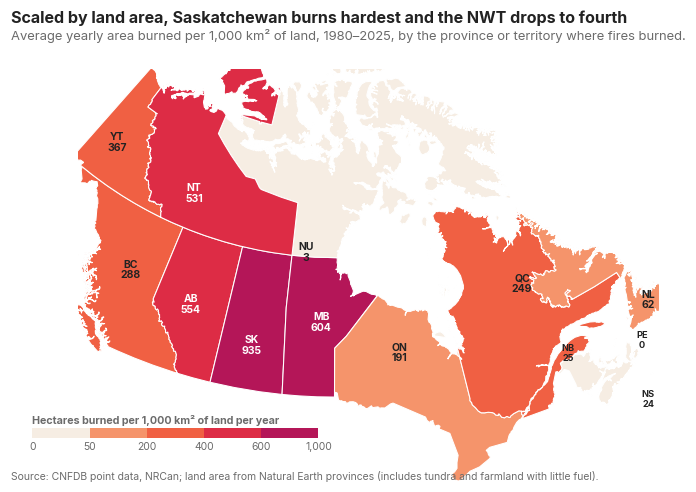

{'rate': {'SK': 935.0,
  'MB': 604.0,
  'AB': 554.0,
  'NT': 531.0,
  'YT': 367.0,
  'BC': 288.0,
  'QC': 249.0,
  'ON': 191.0,
  'NL': 62.0,
  'NB': 25.0,
  'NS': 24.0,
  'NU': 3.0,
  'PE': 0.0}}

In [27]:
fig, facts = fig11_burn_rate_map(df)
st.save(fig, "fig11_burn_rate_map")
plt.show()
facts

## 7. Conclusions
1. **Q1 (trend and 2023).** Canada reports fewer fires each year (a significant decline since 1980), but area burned has no significant linear trend: it is dominated by extreme seasons. 2023 burned 17.6 Mha, twice any other year, started early (record May) and burned in five jurisdictions at once; 2025 (8.7 Mha) is the second-largest year, so 2023 was not an isolated spike.
2. **Q2 (lightning vs people).** The two causes are different problems. People start more than half of all fires, mostly in spring and near settlements, and those fires stay small. Lightning starts fewer fires, in mid-summer across the remote boreal interior, and burns 84% of the land.
3. **Q3 (concentration and size).** Area burned is extremely concentrated: 5% of fires burn 99% of the area. Among fires that escape past 1 ha, the typical lightning fire has grown steadily since 1980; human fires have not.
4. **Q4 (hotspots).** The fire belt is stable in latitude, but burning per year doubled in the 2020s and its centre moved roughly 370 km west. Scaled by land area, the Prairie provinces (Saskatchewan, Manitoba, Alberta) burn hardest.

**Limitations.** Reporting is incomplete before 1980 and starts late in New Brunswick (1980) and PEI (2018); the 2020s hold six seasons (five for polygons); trends are associations, not causes, and are confounded with changing suppression policy and better satellite mapping; cause is Unknown for 4% of the area.